# Formation of energy band

('band_formation_schematic.png',
 'band_formation_schematic.svg',
 1.308457583455289)

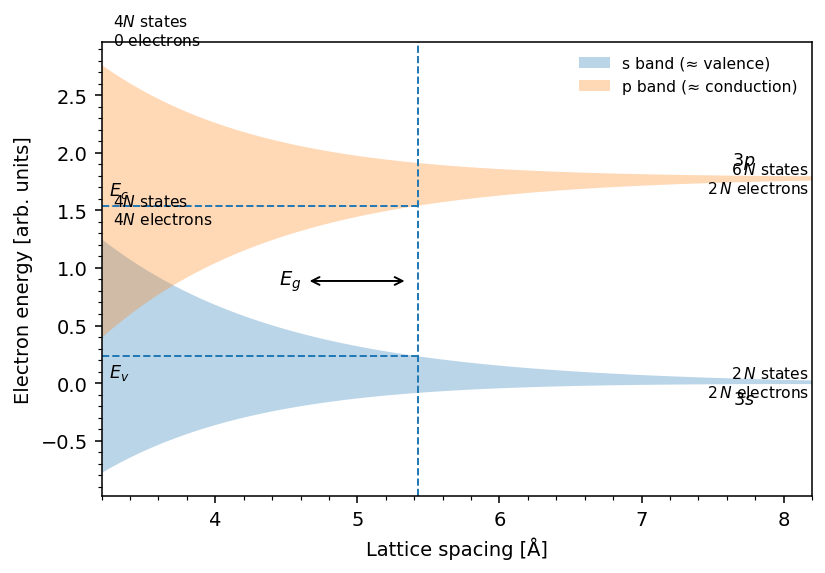

In [2]:
# Computational schematic for band formation vs lattice spacing
# - Generates a didactic plot similar to textbook "atomic → band" diagram
# - Pure matplotlib (no seaborn), single figure, no explicit color choices
#
# You can tweak parameters (centers, widths, decay scales) to match your preferred look.
import numpy as np
import matplotlib.pyplot as plt

# ---------- Model (toy, parametric) ----------
def smooth_clip(x, lo, hi, k=20.0):
    """Smoothly clamp x into [lo,hi] using a sigmoid-like transition (for nicer shapes)."""
    s_lo = 1/(1+np.exp(-k*(x-lo)))
    s_hi = 1/(1+np.exp(-k*(hi-x)))
    return x*s_lo*s_hi + lo*(1-s_lo) + hi*(1-s_hi)

def band_centers(a, Es_inf=0.0, Ep_inf=1.8, a_ref=5.43, slope=-0.08):
    """
    Toy 'atomic level' centers that weakly vary with a (so the envelope has curvature).
    Es approaches Es_inf, Ep approaches Ep_inf as a increases.
    """
    # Light curvature so the 'necks' look like the textbook sketch
    Es = Es_inf + 0.25*np.exp(-(a-3.0)/2.0) + slope*(a-a_ref)*0.05
    Ep = Ep_inf - 0.25*np.exp(-(a-3.0)/2.0) + slope*(a-a_ref)*0.02
    return Es, Ep

def band_widths(a, Ws0=2.4, Wp0=2.8, ascale=1.2):
    """
    Overlap ~ exp(-a/ascale) so bands narrow with increasing a (atomic limit).
    Larger width at small a to mimic strong overlap.
    """
    Ws = Ws0*np.exp(-(a-3.0)/ascale)
    Wp = Wp0*np.exp(-(a-3.0)/ascale)
    return Ws, Wp

def sp_bands(a):
    """
    Construct s- and p-like bands: lower/upper envelopes for each.
    When the s upper edge crosses the p lower edge, they 'touch/overlap' (metallic).
    """
    Es, Ep = band_centers(a)
    Ws, Wp = band_widths(a)
    s_lower, s_upper = Es - 0.5*Ws, Es + 0.5*Ws
    p_lower, p_upper = Ep - 0.5*Wp, Ep + 0.5*Wp
    return s_lower, s_upper, p_lower, p_upper

# ---------- Plot ----------
a = np.linspace(3.2, 8.2, 500)            # lattice spacing [Å]
s_lo, s_hi, p_lo, p_hi = sp_bands(a)

a_si = 5.43
# Interpolate edges at silicon spacing
Ev = np.interp(a_si, a, s_hi)
Ec = np.interp(a_si, a, p_lo)
Eg = Ec - Ev

fig, ax = plt.subplots(figsize=(6.0, 4.2), dpi=140)

# Shade 'valence' (s) and 'conduction' (p) regions as filled bands
ax.fill_between(a, s_lo, s_hi, alpha=0.3, label="s band (≈ valence)")
ax.fill_between(a, p_lo, p_hi, alpha=0.3, label="p band (≈ conduction)")

# Vertical marker at 5.43 Å
ax.axvline(a_si, linestyle="--", linewidth=1)

# Horizontal markers for Ev and Ec at a=5.43 Å
ax.hlines([Ev, Ec], xmin=a.min(), xmax=a_si, linestyles="dashed", linewidth=1)

# Annotate Ec, Ev, Eg
ax.text(a.min()+0.05, Ec+0.05, r"$E_c$", fontsize=9, va="bottom")
ax.text(a.min()+0.05, Ev-0.05, r"$E_v$", fontsize=9, va="top")
ax.annotate(r"$E_g$", xy=(a_si-0.07, (Ec+Ev)/2),
            xytext=(a_si-0.9, (Ec+Ev)/2),
            arrowprops=dict(arrowstyle="<->", linewidth=1),
            ha="center", va="center")

# Labels for atomic limits on the right
ax.text(a.max()-0.4, np.interp(a.max(), a, s_lo)-0.05, r"$3s$", ha="right", va="top", fontsize=9)
ax.text(a.max()-0.4, np.interp(a.max(), a, p_hi)+0.05, r"$3p$", ha="right", va="bottom", fontsize=9)

# Degeneracy annotations (didactic; 2 spin states × N k-points for s; 6N for p in diamond-like)
ax.text(a.max()-0.02, np.interp(a.max(), a, s_lo)+(np.interp(a.max(), a, s_hi)-np.interp(a.max(), a, s_lo))/2,
        r"$2\,N$ states"+"\n"+r"$2\,N$ electrons",
        ha="right", va="center", fontsize=8)
ax.text(a.max()-0.02, np.interp(a.max(), a, p_lo)+(np.interp(a.max(), a, p_hi)-np.interp(a.max(), a, p_lo))/2,
        r"$6\,N$ states"+"\n"+r"$2\,N$ electrons",
        ha="right", va="center", fontsize=8)

# Left-side occupancy note near small a (optional, purely schematic)
ax.text(a.min()+0.08, np.interp(a.min(), a, s_hi)+0.1, r"$4N$ states"+"\n"+r"$4N$ electrons", fontsize=8, va="bottom")
ax.text(a.min()+0.08, np.interp(a.min(), a, p_hi)+0.15, r"$4N$ states"+"\n"+r"$0$ electrons", fontsize=8, va="bottom")

# Axis labels and limits
ax.set_xlabel("Lattice spacing [Å]")
ax.set_ylabel("Electron energy [arb. units]")
ax.set_xlim(a.min(), a.max())
ax.set_ylim(min(s_lo.min(), p_lo.min())-0.2, max(s_hi.max(), p_hi.max())+0.2)

# Ticks and minor aesthetic choices
ax.minorticks_on()
ax.legend(loc="upper right", fontsize=8, frameon=False)

# Save files for reuse
out_png = "band_formation_schematic.png"
out_svg = "band_formation_schematic.svg"
fig.tight_layout()
fig.savefig(out_png, bbox_inches="tight")
fig.savefig(out_svg, bbox_inches="tight")

(out_png, out_svg, float(Eg))
